In [1]:
import sys
sys.path.append('..')
%load_ext autoreload
%autoreload 2

from guided_flow.utils.visualize import visualize_traj_and_vf

from guided_flow.backbone.mlp import MLP
from guided_flow.backbone.wrapper import MLPWrapper, GuidedMLPWrapper
from guided_flow.config.sampling import GuideFnConfig, ODEConfig
from guided_flow.distributions.base import get_distribution
from guided_flow.utils.misc import deterministic, get_device
from guided_flow.guidance.gradient_guidance import wrap_grad_fn
import torch
from torchdyn.core import NeuralODE
import numpy as np

from dataclasses import dataclass
import matplotlib.pyplot as plt
import matplotlib.cm as cm


MLP_WIDTH = 256
CFM = 'cfm'
X_LIM = 2
Y_LIM = 2
DISP_TRAJ_BATCH = 256

@dataclass
class LocalODEConfig:
    seed: int = 0
    device: str = get_device()
    batch_size: int = 2048
    num_steps: int = 200
    solver: str = 'euler'

cfg = LocalODEConfig()

deterministic(cfg.seed)

def evaluate_unconditional(x0_sampler, x1_sampler, model, cfg: LocalODEConfig):
    node = NeuralODE(
        MLPWrapper(model), 
        solver="euler", sensitivity="adjoint")

    with torch.no_grad():
        traj = node.trajectory(
            x0_sampler(cfg.batch_size).to(cfg.device), 
            t_span=torch.linspace(0, 1, cfg.num_steps)
        )
    
    return traj

class GuidanceWrapper(torch.nn.Module):
    def __init__(self, model, guide_fn):
        super().__init__()
        self.model = model
        self.guide_fn = guide_fn
        
    def forward(self, t, x, *args, **kwargs):
        dx_dt = self.model(torch.cat([x, t.repeat(x.shape[0])[:, None]], 1))
        return self.guide_fn(t, x, dx_dt, self.model)

def get_guide_fn(dist, cfg):
    def guide_fn(t, x, dx_dt, model):
        if cfg.guide_type == 'g_cov_A':
            x1_pred = x + dx_dt * (1 - t)
            try:
                with torch.enable_grad():
                    x1_pred = x1_pred.requires_grad_(True)
                    J = dist.get_J(x1_pred)
                    grad = -torch.autograd.grad(J.sum(), x1_pred, create_graph=True)[0]
                    return grad
            except Exception as e:
                return torch.zeros_like(x)
        elif cfg.guide_type == 'g_cov_G':
            with torch.enable_grad():
                x = x.requires_grad_(True)
                x1_pred = x + model(torch.cat([x, t.repeat(x.shape[0])[:, None]], 1)) * (1 - t)
                J = dist.get_J(x1_pred)
                try:
                    grad = -torch.autograd.grad(J.sum(), x, create_graph=True)[0]
                    return grad
                except Exception as e:
                    return torch.zeros_like(x)
        else:
            raise ValueError(f"Unknown guide function: {cfg.guide_type}")
    return wrap_grad_fn(cfg.guide_scale, cfg.guide_schedule, guide_fn)


/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/torchvision/io/image.py:14: UserWarning: Failed to load image Python extension: 'dlopen(/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/torchvision/image.so, 0x0006): Library not loaded: @rpath/libjpeg.9.dylib
  Referenced from: <367D4265-B20F-34BD-94EB-4F3EE47C385B> /Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/torchvision/image.so
  Reason: tried: '/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/torchvision/../../../libjpeg.9.dylib' (no such file), '/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/lib-dynload/../../libjpeg.9.dylib' (no such file), '/Users/LS/miniconda3/envs/bio_ml/bin/../lib/libjpeg.9.dylib' (no such file)'If you don't plan on using image functionality from `torchvision.io`, you can ignore this warning. Otherwise, there might be something wrong with

Evaluating uniform -> 8gaussian


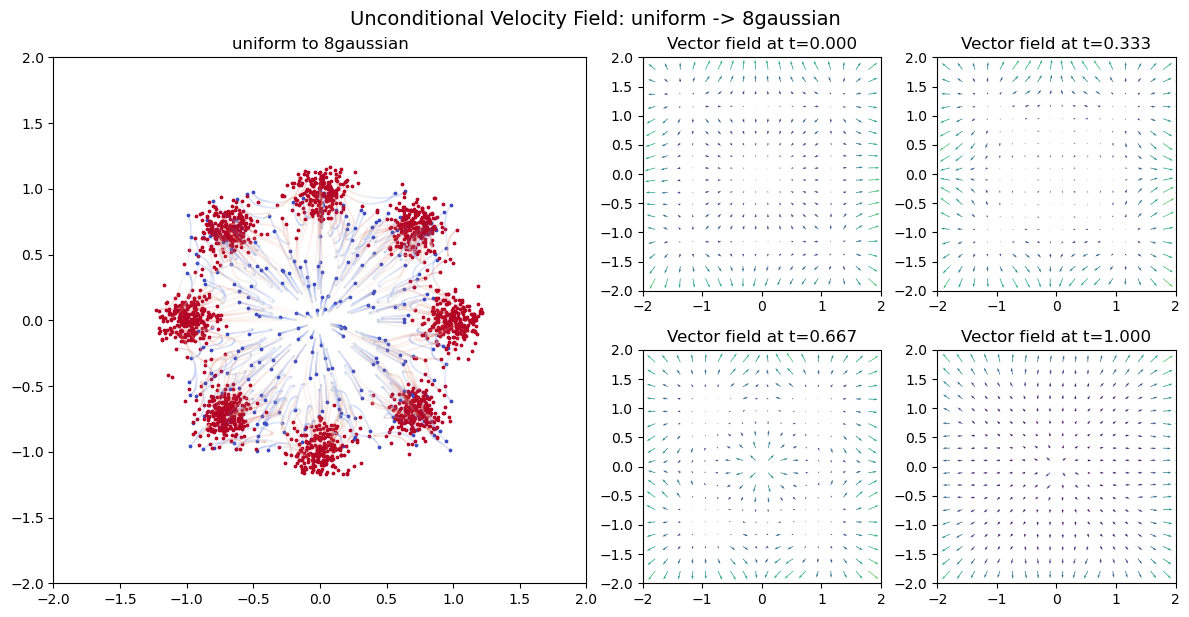

/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/matplotlib/quiver.py:695: RuntimeWarning: divide by zero encountered in scalar divide
  length = a * (widthu_per_lenu / (self.scale * self.width))
/Users/LS/miniconda3/envs/bio_ml/lib/python3.12/site-packages/matplotlib/quiver.py:695: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


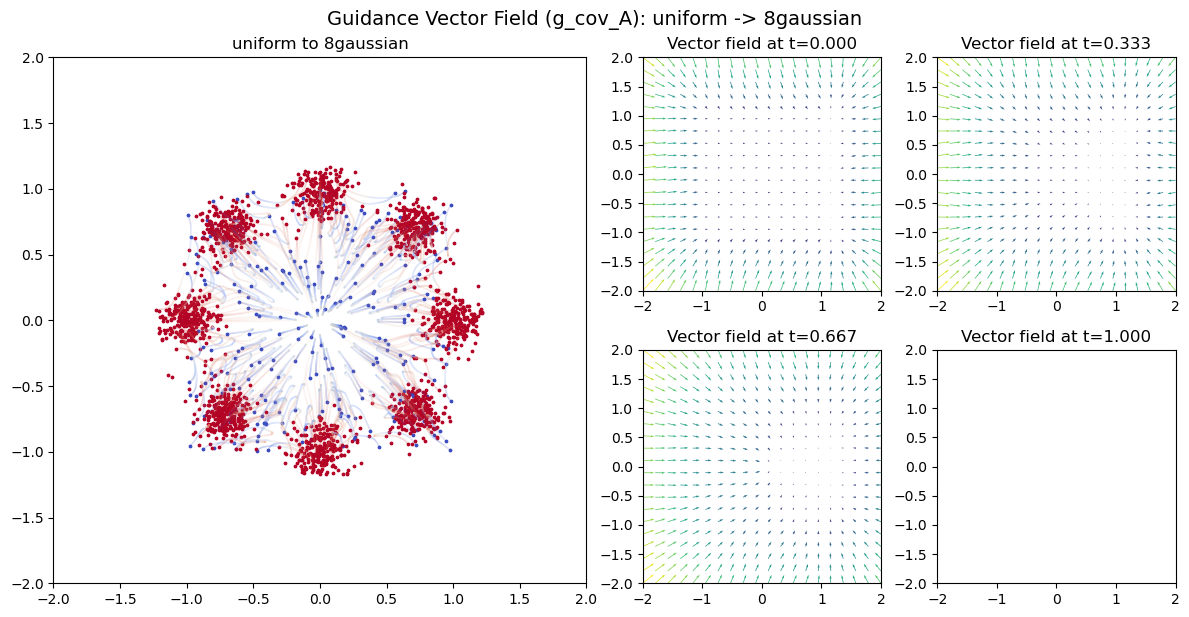

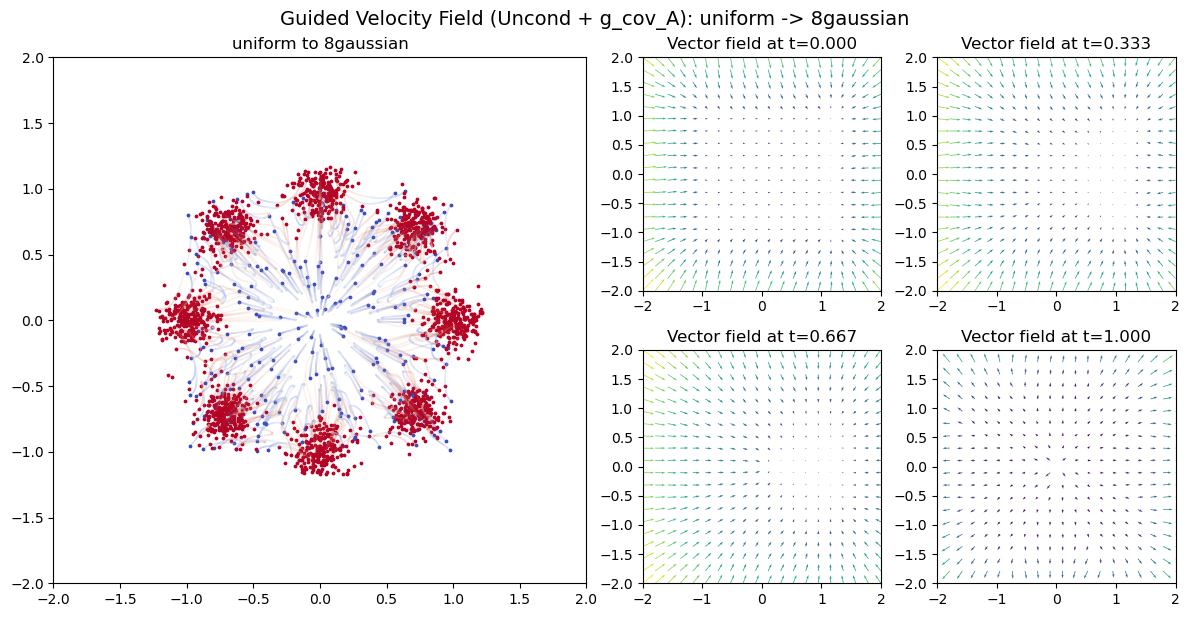

Evaluating 8gaussian -> moon


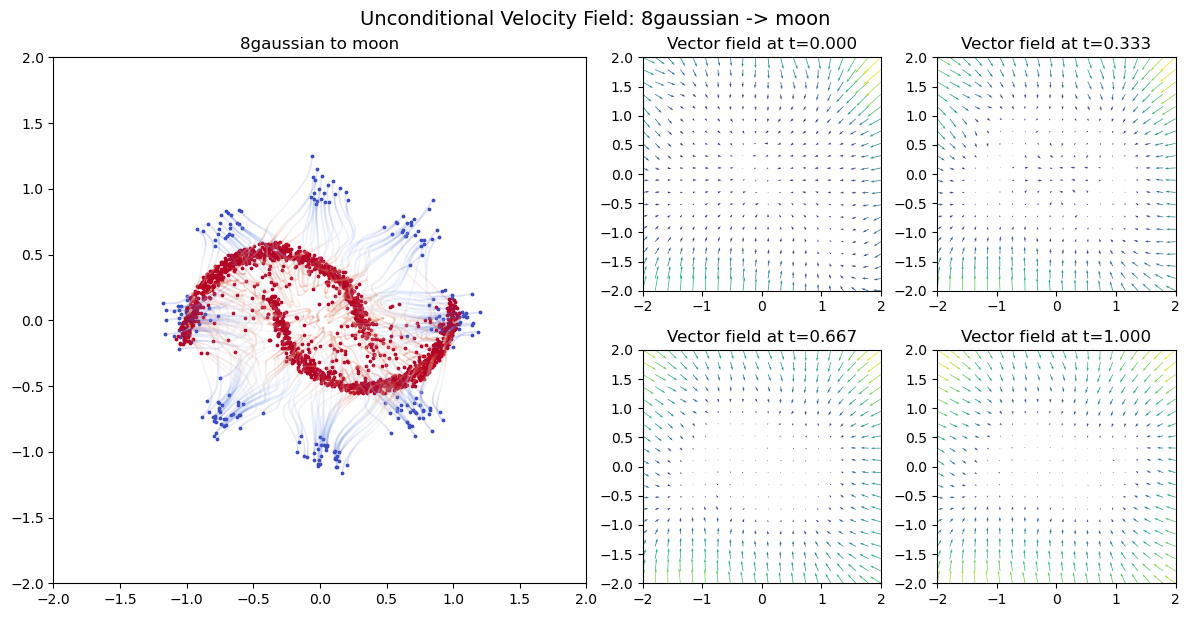

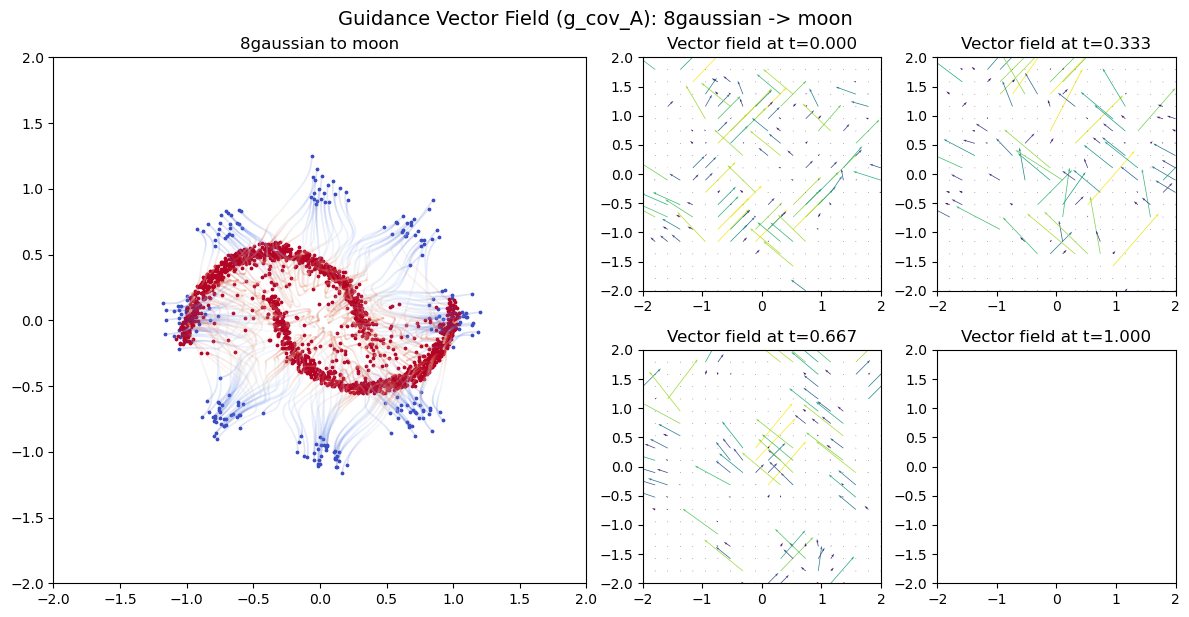

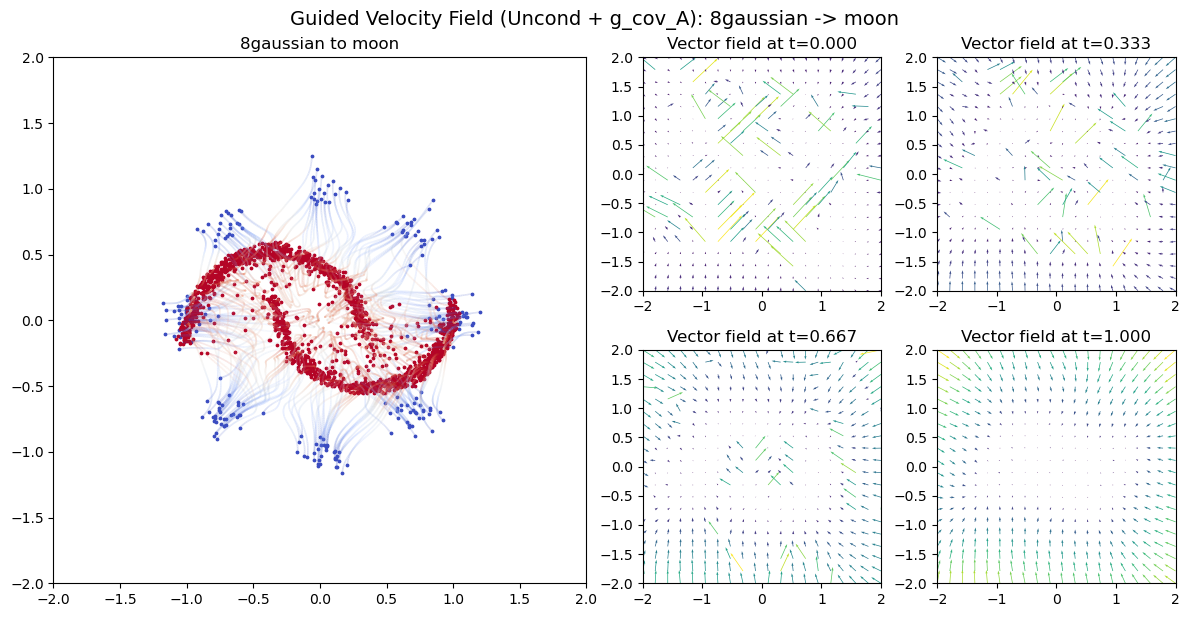

Evaluating gaussian -> circle


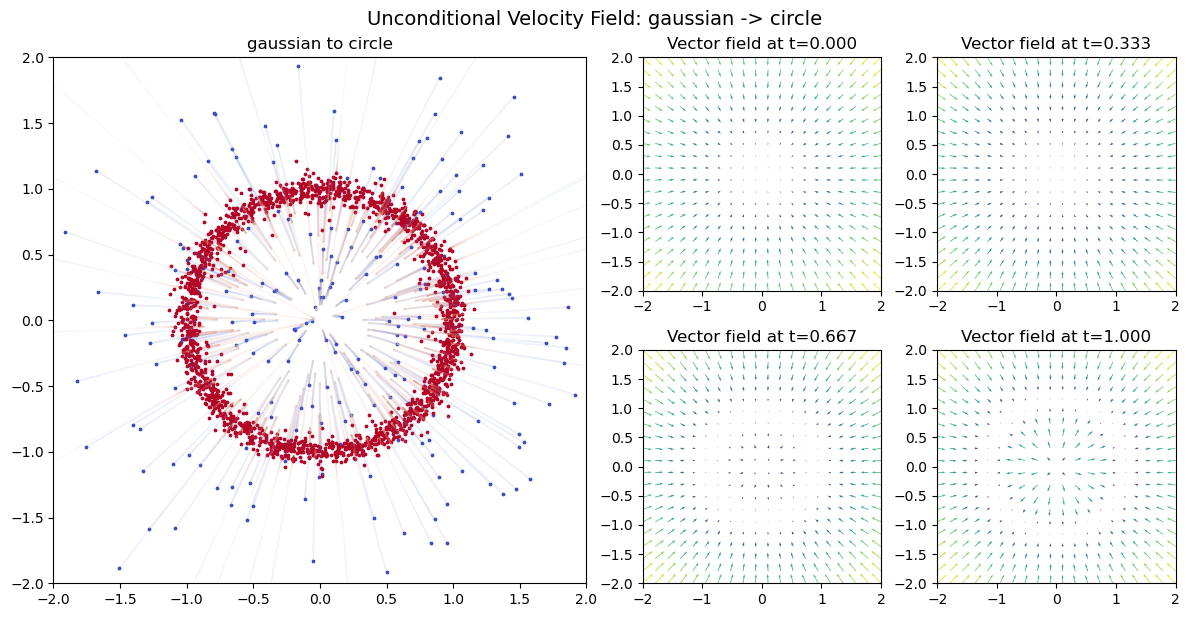

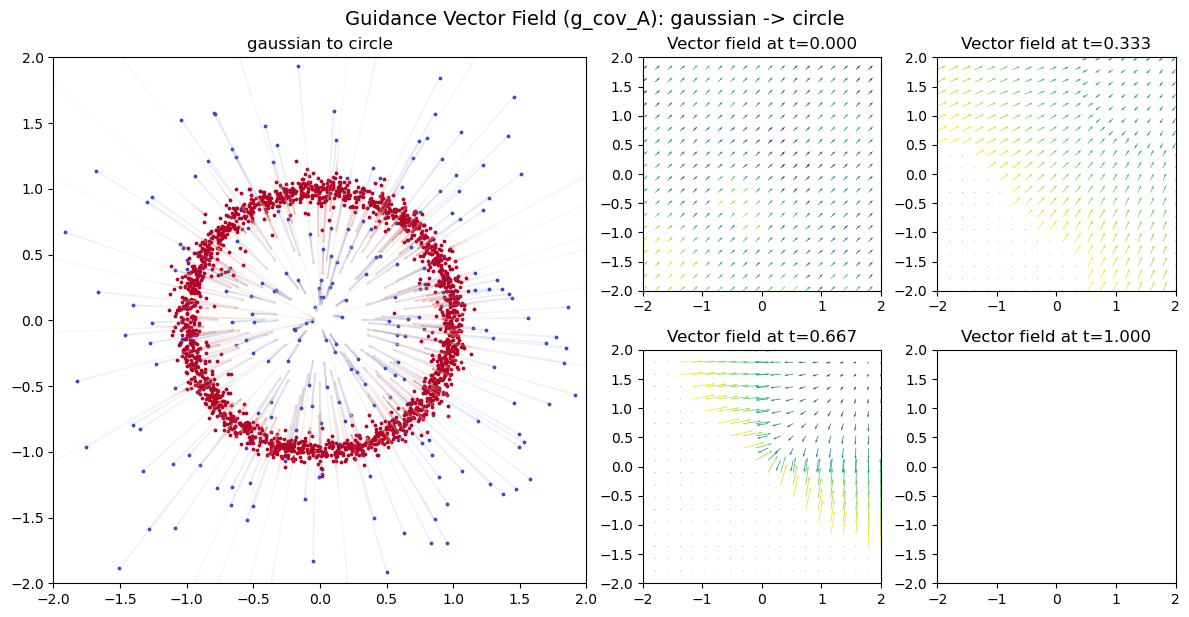

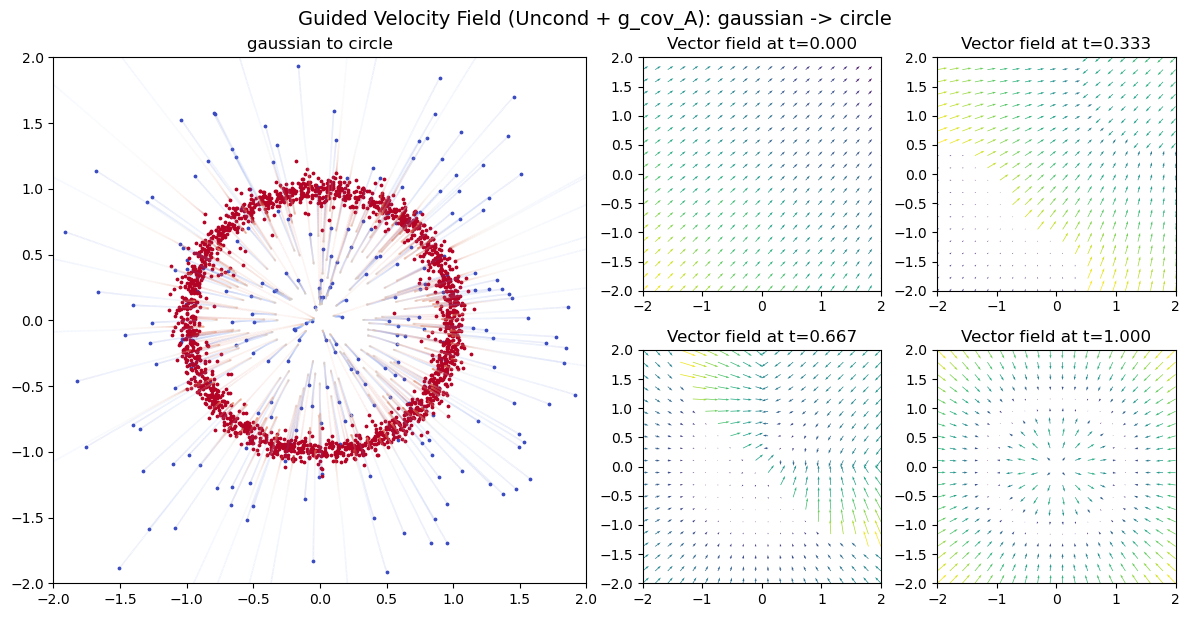

In [2]:
dist_pairs = [
    ('uniform', '8gaussian'),
    ('8gaussian', 'moon'),
    ('gaussian', 'circle'),
]
for x0_dist, x1_dist in dist_pairs:
    print(f"=========================================")
    print(f"Evaluating {x0_dist} -> {x1_dist}")
    print(f"=========================================")
    
    x0_sampler = get_distribution(x0_dist).sample
    x1_sampler = get_distribution(x1_dist).sample

    model = MLP(dim=2, w=MLP_WIDTH, time_varying=True).to(cfg.device)
    model.load_state_dict(torch.load(f'../logs/{x0_dist}-{x1_dist}/{CFM}_{x0_dist}_{x1_dist}/{CFM}_{x0_dist}_{x1_dist}.pth', map_location='cpu', weights_only=True))
    
    traj = evaluate_unconditional(x0_sampler, x1_sampler, model, cfg)

    # 1. Unconditional velocity field
    wrapped_model = MLPWrapper(model)
    fig, axs = visualize_traj_and_vf(
        traj, 
        wrapped_model, 
        cfg.num_steps, 
        x0_dist, 
        x1_dist, 
        cfg.device, 
        disp_traj_batch=DISP_TRAJ_BATCH, 
        x_lim=X_LIM, 
        y_lim=Y_LIM
    )
    fig.suptitle(f"Unconditional Velocity Field: {x0_dist} -> {x1_dist}", fontsize=14, y=1.02)
    plt.show()

    # 2. Guidance Vector Field Only (g_cov_A)
    x1_dist_obj = get_distribution(x1_dist)
    guide_cfg = GuideFnConfig(
        dist_pair=(x0_dist, x1_dist), 
        guide_type='g_cov_A', 
        guide_scale=1.0, 
        guide_schedule='linear_decay'
    )
    guide_fn = get_guide_fn(x1_dist_obj, guide_cfg)
    
    guidance_wrapped = GuidanceWrapper(model, guide_fn)
    fig_g, _ = visualize_traj_and_vf(
        traj, 
        guidance_wrapped, 
        cfg.num_steps, 
        x0_dist, 
        x1_dist, 
        cfg.device, 
        disp_traj_batch=DISP_TRAJ_BATCH, 
        x_lim=X_LIM, 
        y_lim=Y_LIM
    )
    fig_g.suptitle(f"Guidance Vector Field (g_cov_A): {x0_dist} -> {x1_dist}", fontsize=14, y=1.02)
    plt.show()

    # 3. Guided Velocity Field (Combined)
    guided_wrapped = GuidedMLPWrapper(model, guide_fn)
    fig_guided, _ = visualize_traj_and_vf(
        traj, 
        guided_wrapped, 
        cfg.num_steps, 
        x0_dist, 
        x1_dist, 
        cfg.device, 
        disp_traj_batch=DISP_TRAJ_BATCH, 
        x_lim=X_LIM, 
        y_lim=Y_LIM
    )
    fig_guided.suptitle(f"Guided Velocity Field (Uncond + g_cov_A): {x0_dist} -> {x1_dist}", fontsize=14, y=1.02)
    plt.show()


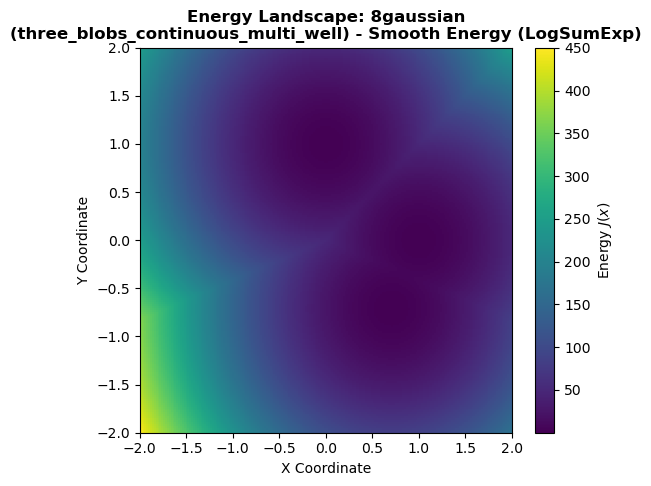

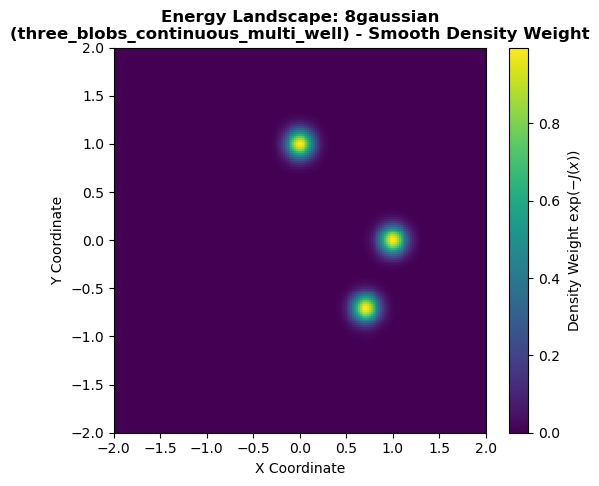

In [3]:
# ============================================================
# Energy Landscape Visualization
# ============================================================

def plot_energy_landscape(dist_name: str, energy_fn_name: str = None, custom_fn = None, energy_kwargs: dict = None, x_range=(-2.0, 2.0), y_range=(-2.0, 2.0), grid_resolution=200, plot_exp=False, title_suffix=""):
    """
    Plots the specified energy function or custom function of a distribution over the grid range.
    """
    # Instantiate distribution
    dist = get_distribution(dist_name, energy_fn=energy_fn_name if custom_fn is None else None, **(energy_kwargs or {}))
    
    # Generate coordinates grid
    x = torch.linspace(x_range[0], x_range[1], grid_resolution)
    y = torch.linspace(y_range[0], y_range[1], grid_resolution)
    X, Y = torch.meshgrid(x, y, indexing='xy')
    XY = torch.stack([X.flatten(), Y.flatten()], dim=-1)
    
    # Evaluate the function
    with torch.no_grad():
        if custom_fn is not None:
            values = custom_fn(XY).reshape(grid_resolution, grid_resolution)
        else:
            values = dist.get_J(XY).reshape(grid_resolution, grid_resolution)
            
        if plot_exp:
            values = torch.exp(-values)
        
    # Plot using matplotlib
    fig, ax = plt.subplots(figsize=(6, 5))
    mesh = ax.pcolormesh(X.numpy(), Y.numpy(), values.numpy(), cmap='viridis', shading='auto')
    label = 'Density Weight $\\exp(-J(x))$' if plot_exp else 'Energy $J(x)$'
    fig.colorbar(mesh, ax=ax, label=label)
    
    ax.set_xlabel('X Coordinate')
    ax.set_ylabel('Y Coordinate')
    
    # Resolve descriptive name for title
    fn_name = energy_fn_name or (custom_fn.__name__ if custom_fn else dist.energy_fn_name)
    title = f"Energy Landscape: {dist_name}\n({fn_name})"
    if title_suffix:
        title += f" - {title_suffix}"
        
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlim(x_range)
    ax.set_ylim(y_range)
    plt.show()
    return fig, ax

# Helper function: raw minimum squared distance to target centers (without log-sum-exp / exponential)
def three_blobs_multi_well_no_exp(x, target_indices=[0, 2, 5]):
    dist_obj = get_distribution('8gaussian')
    target_centers = dist_obj.centers[target_indices].to(x.device)
    sq_dists = torch.sum((x.unsqueeze(1) - target_centers.unsqueeze(0)) ** 2, dim=-1) # Shape: (B, 3)
    return torch.min(sq_dists, dim=-1)[0]

# --- 1. Continuous Multi-Well (smooth with LogSumExp) ---
_ = plot_energy_landscape(
    dist_name='8gaussian', 
    energy_fn_name='three_blobs_continuous_multi_well',
    title_suffix="Smooth Energy (LogSumExp)"
)

# --- 2. Smooth Density Weight exp(-J(x)) (exponential of negative energy) ---
_ = plot_energy_landscape(
    dist_name='8gaussian', 
    energy_fn_name='three_blobs_continuous_multi_well',
    plot_exp=True,
    title_suffix="Smooth Density Weight"
)
